# Prerequisite 03 · Matplotlib：读懂训练曲线

[上一章：NumPy](Prerequisite02_NumPy.ipynb) · [下一章：数学](Prerequisite04_Math.ipynb)

**目标：**画原始回报、移动平均、多随机种子均值和置信带，并知道曲线不能单独证明算法优劣。


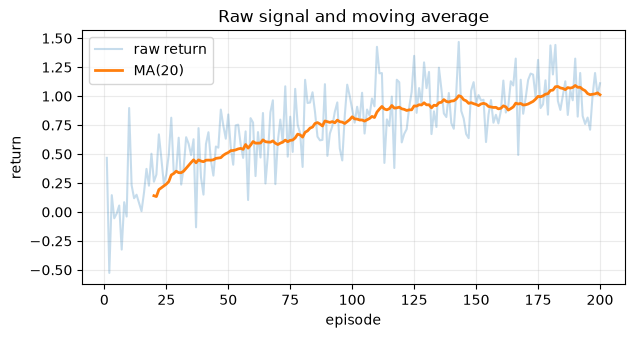

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)
episodes = np.arange(1, 201)
raw_return = 1 - np.exp(-episodes/55) + rng.normal(0, .22, len(episodes))
window = 20
smooth = np.convolve(raw_return, np.ones(window)/window, mode="valid")

plt.figure(figsize=(7, 3.3))
plt.plot(episodes, raw_return, alpha=.25, label="raw return")
plt.plot(episodes[window-1:], smooth, linewidth=2, label=f"MA({window})")
plt.xlabel("episode"); plt.ylabel("return"); plt.title("Raw signal and moving average")
plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()


## 1. 移动平均做了什么

它降低可视噪声，但会引入滞后，且不能增加数据。窗口越大越平滑，也越容易掩盖突然坍缩。正式报告应说明窗口大小，并保留原始数据。


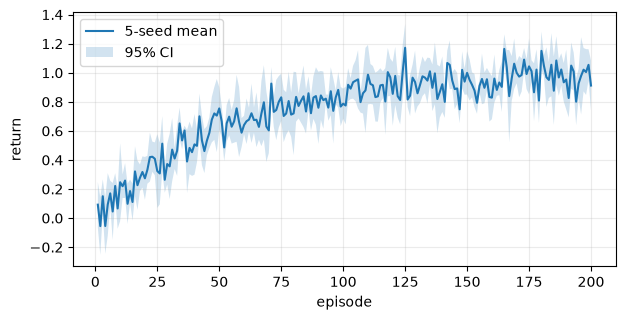

final mean: 0.972


In [2]:
# 五个 seed 才是五次独立实验；200 个 episode 不是 200 个独立 seed。
runs = np.stack([
    1 - np.exp(-episodes/(45 + 4*seed)) + np.random.default_rng(seed).normal(0, .18, len(episodes))
    for seed in range(5)
])
mean = runs.mean(axis=0)
sem = runs.std(axis=0, ddof=1) / np.sqrt(len(runs))

plt.figure(figsize=(7, 3.3))
plt.plot(episodes, mean, label="5-seed mean")
plt.fill_between(episodes, mean-1.96*sem, mean+1.96*sem, alpha=.2, label="95% CI")
plt.xlabel("episode"); plt.ylabel("return"); plt.grid(alpha=.25); plt.legend();
plt.show(); plt.close()
print("final mean:", round(mean[-20:].mean(), 3))


## 2. 曲线阅读顺序

1. 横轴是什么：episode、环境帧、gradient step 还是 wall-clock？
2. 任务指标是什么：return、success rate、episode length？
3. 优化指标是否对应：loss、entropy、KL、Q scale？
4. 有几个 seed，阴影代表标准差、标准误还是置信区间？
5. 曲线是训练策略还是关闭探索后的独立评估？

**失败案例：**只画最好 seed；平滑窗口大到遮住坍缩；不同算法使用不同样本预算；只画 loss 不画任务回报。


## 练习与过关标准

**练习：**把窗口改为 5、50，解释变化；然后让一个 seed 在第 150 回合坍缩，观察均值和置信带。

**过关：**能独立画 raw + moving average；能画多 seed 均值与置信带；能指出一张图还缺少哪些实验信息。

**官方选读：**[Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)，优先看 Quick start 和 Pyplot tutorial。
